In [483]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb,g
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from slmsuite.holography.toolbox.phase import zernike_sum,zernike_get_string,ZERNIKE_NAMES 
from src.algos import *
from src.zernike import get_zernike_calibrations,get_cholo_phase,get_cholo_bb_g_phase,fit_metric,fit_metric_udf,plot_parabola,get_zernike_dict_from_metrics_df,get_zernike_metrics_df,zernike_names,refine_centers,get_zernike_data
from src import global_store

import pandas as pd
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Initialise SLM and camera setup

### creates an object fs (which has camera and slm accessed via fs.slm,fs.camera)

In [484]:
fs = slm_initialise(force=True,verbose=True)

Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
Looking for cameras... success
ThorCam sn '12975' initializing... success


### Writing a phase mask which is all zeros and checking the output to see everything is working

c:\Users\QC\Envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 2],
       [1, 1, 1, ..., 2, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 2, 1, ..., 2, 1, 2],
       [2, 1, 1, ..., 1, 2, 1]], dtype=uint16)

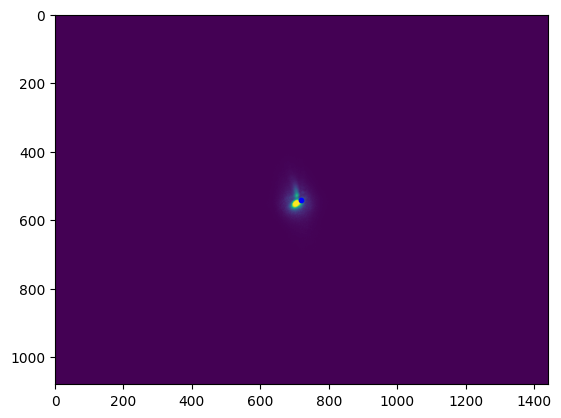

In [3]:
plot_cam(fs,phase="zero",centre=True, save=True)

#  Calibrations 


### The calibrate() function does the fourier calibration between camera and fourier/frequency domain of slm, It does a affine fitting to account for tilt of the camera and scaling from the lens setup.
#####           vendor = True loads the vendors saved calibration (I am ignoring it since it didnt give much benefit)
#####           it also calibrates settle time of writing a phase mask to slm. So camera images can be captured after this settle time by setting settle = True if further functions

### sp_calibrate does the superpixel calibration to correct the aberrations

#### Here the refresh = false loads the pre saved calibrations

smooth:   0%|          | 0/16 [00:00<?, ?it/s]

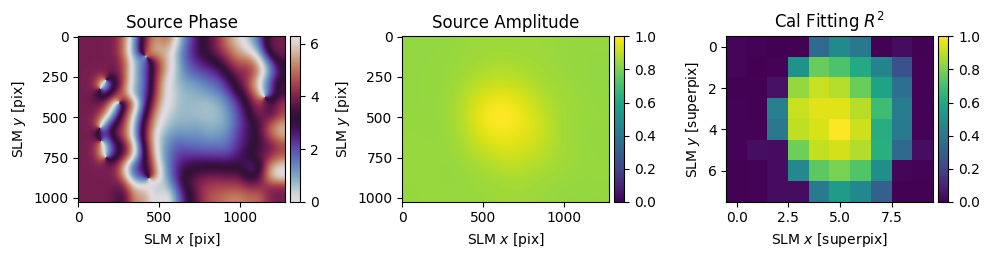

array([[2, 1, 1, ..., 1, 1, 1],
       [1, 2, 1, ..., 1, 2, 1],
       [1, 1, 1, ..., 1, 2, 1],
       ...,
       [1, 2, 2, ..., 1, 1, 1],
       [1, 2, 1, ..., 2, 1, 1],
       [2, 2, 1, ..., 1, 2, 1]], dtype=uint16)

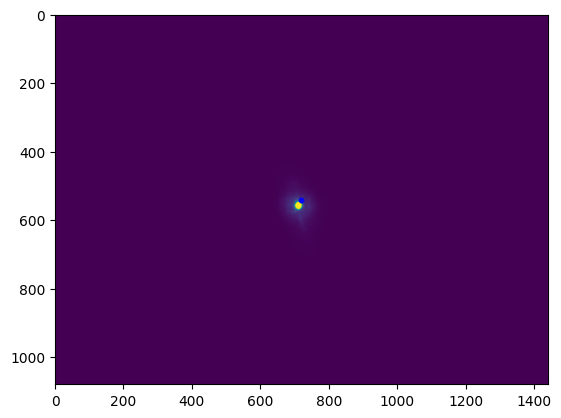

In [4]:
calibrate(fs,vendor = False,refresh = False)
sp_calibrate(fs,refresh=False)
plot_cam(fs,phase="zero",centre=True, save=True)

# Tweezer Array

### Now lets see how we can make an array of tweezers and correct their uniformities

#### Step 1 : Shift the zeroth order by moving the camera till it reaches the desired blaze location

In [198]:
blaze_location = [1440-50,540]
blaze_shift = [blaze_location[1] - fs.cam.shape[0]//2 ,blaze_location[0] - fs.cam.shape[1]//2]
blaze_phase = torch.tensor(toolbox.phase.blaze(
    grid = fs.slm,       
    vector=toolbox.convert_vector(vector=blaze_location,from_units="ij",to_units="norm",hardware=fs)
)
)

array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 2, 1, 1],
       [1, 1, 2, ..., 1, 2, 2],
       ...,
       [1, 1, 1, ..., 1, 2, 1],
       [1, 2, 2, ..., 2, 2, 1],
       [2, 2, 1, ..., 1, 2, 1]], dtype=uint16)

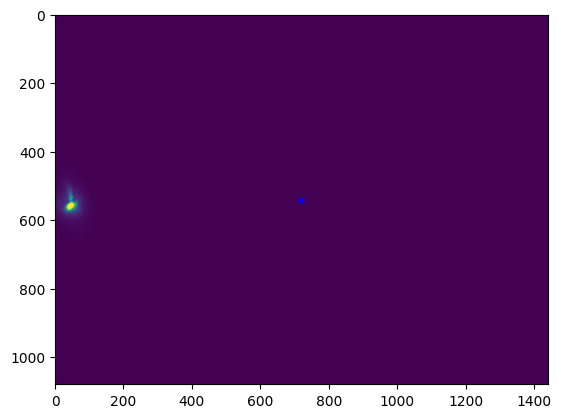

In [195]:
plot_cam(fs,phase="zero",centre=True, save=True)

#### Step 2 : create an array of tweezer locations say 500 and use gerchberg saxton algorithm to create the phase mask

In [295]:
spot_vectors = np.array([[ 44*(i+4),44*(j+3)] for i in range(25) for j in range(20)])

In [296]:
phi_nf_gs,phi_ff_gs = gs_spots(spot_vectors = spot_vectors,fs=fs,n_iters = 100)

1.0019999999999991
0.0019388101787984643
0.005018301072795665
0.004674411175845159
0.00457866013152641
0.004578658840394095
0.004567709328782506
0.004389899361380082
0.0034471673044401416
0.001751094381416088
0.0007595072957886767
0.00037851162281243465
0.00023139898212291051
0.00016872670519963936
0.0001371123846648031
0.00011860545375797705
0.00010628190551079512
9.742060917276404e-05
9.082511294306801e-05
8.583326945469863e-05
8.19145731908078e-05
7.876334030696439e-05
7.615929090293256e-05
7.393165401474702e-05
7.204527427150768e-05
7.046167892489592e-05
6.910912589583262e-05
6.793905086997813e-05
6.692092439364781e-05
6.605400546370798e-05
6.531669850912037e-05
6.465686355949245e-05
6.40536905126112e-05
6.351600955800687e-05
6.302472635980021e-05
6.260105237859882e-05
6.220664274296616e-05
6.182199568147637e-05
6.145476953326862e-05
6.110686780952967e-05
6.076290257358677e-05
6.042731451967202e-05
6.009874439935991e-05
5.9784954172382404e-05
5.948219838194534e-05
5.919823279953176

In [297]:
spots_phase = phi_nf_gs + blaze_phase

array([[2, 2, 1, ..., 1, 1, 1],
       [1, 1, 2, ..., 1, 2, 1],
       [1, 1, 2, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 2, 2, 1],
       [2, 1, 2, ..., 2, 1, 2],
       [1, 1, 2, ..., 1, 1, 1]], dtype=uint16)

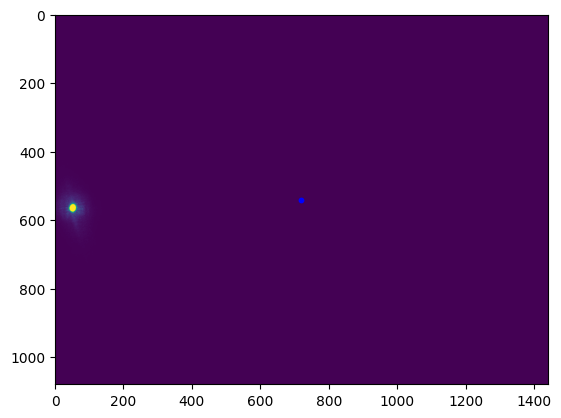

In [ ]:
# calibrate(fs,vendor = False,refresh = False)
# sp_calibrate(fs,refresh=False)
plot_cam(fs,phase="zero",centre=True, save=True)

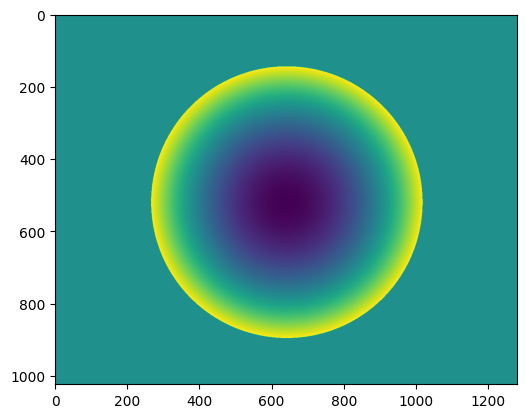

In [353]:
plt.imshow( zernike(fs.slm, 4))

In [382]:
fs.slm.set_phase(spots_phase.numpy())

array([[ 65,  19,   5, ..., 178, 170, 156],
       [ 90, 230, 225, ..., 158, 155, 150],
       [103, 173, 188, ..., 137, 136, 137],
       ...,
       [108,  96,  84, ..., 191, 180, 169],
       [ 84,  65,  50, ..., 179, 166, 150],
       [ 58,  30,  13, ..., 166, 154, 136]], dtype=uint8)

writing phase


array([[31, 31, 28, ..., 32, 30, 33],
       [28, 29, 31, ..., 37, 33, 31],
       [29, 30, 33, ..., 30, 36, 29],
       ...,
       [31, 30, 31, ..., 37, 36, 35],
       [32, 33, 31, ..., 37, 38, 40],
       [33, 31, 32, ..., 34, 34, 40]], dtype=uint16)

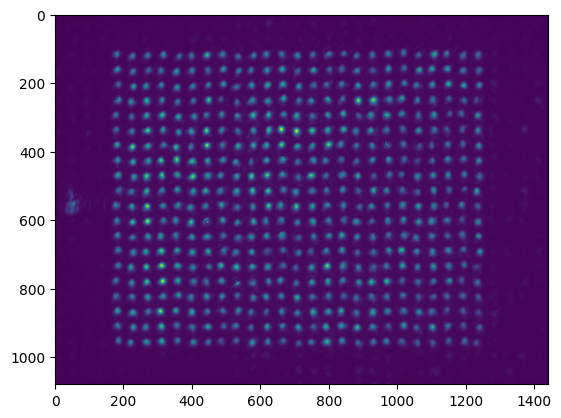

In [490]:
plot_cam(fs,phase=spots_phase.numpy()-0.4*zernike(fs, 4,use_mask = False), save=True,exposure=80)

writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writin

{1: {'w': [-0.5,
   -0.4473684210526316,
   -0.39473684210526316,
   -0.34210526315789475,
   -0.2894736842105263,
   -0.2368421052631579,
   -0.1842105263157895,
   -0.13157894736842107,
   -0.07894736842105265,
   -0.026315789473684237,
   0.02631578947368418,
   0.07894736842105265,
   0.13157894736842102,
   0.18421052631578938,
   0.23684210526315785,
   0.2894736842105263,
   0.3421052631578947,
   0.39473684210526305,
   0.4473684210526315,
   0.5],
  'images': [array([[26, 30, 33, ..., 32, 31, 35],
          [27, 30, 32, ..., 31, 31, 31],
          [30, 30, 28, ..., 29, 31, 31],
          ...,
          [29, 35, 34, ..., 37, 36, 33],
          [33, 30, 33, ..., 38, 38, 33],
          [32, 32, 31, ..., 35, 35, 33]], dtype=uint16),
   array([[29, 32, 28, ..., 33, 35, 31],
          [26, 29, 32, ..., 32, 29, 29],
          [31, 30, 30, ..., 29, 31, 30],
          ...,
          [33, 33, 30, ..., 37, 34, 35],
          [31, 31, 28, ..., 37, 37, 35],
          [30, 33, 32, ..., 33, 

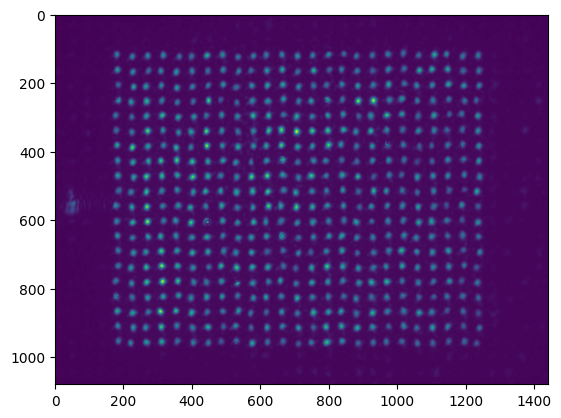

In [491]:
get_zernike_data(base_phase=spots_phase.numpy(),zernike_indices=[i+1 for i in range(10)],file_name = "zernike_data_global_500tweezers")

In [342]:
from PIL import Image
import cv2

In [349]:
phi_wrapped = np.mod(spots_phase.numpy() + fs.slm.source['phase'], 2*np.pi)
phase_8bit = np.uint8(255 * phi_wrapped / (2*np.pi))
cv2.imwrite("phase_mask.bmp", phase_8bit)

True

In [339]:
image = Image.fromarray((spots_phase.numpy()).astype(np.uint8))

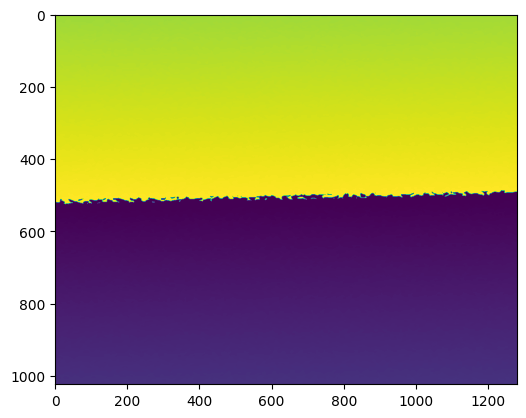

In [335]:
plt.imshow(image)

In [340]:
image.save("tweezer_array_phase.bmp")

# Up correction

In [244]:
spot_weights = np.zeros((spot_vectors.shape[0],5))
spot_weights[:,0] = 1
phis = []

In [245]:
phi_nf_new = get_phi_nf(fs,spot_vectors,phi_ff_gs,spot_weights)

In [246]:
phase = phi_nf_new + blaze_phase

In [247]:
out = plot_cam(fs=fs,phase = phase.numpy(),plot = False,sleep=3)

writing phase


In [248]:
refined_centres = refine_centers(out, expected_centers = spot_vectors, patch_size=50, min_distance=1)

In [249]:
refined_centres[0],spot_vectors[0]

((189, 126), array([176, 132]))

In [250]:
pd.DataFrame(refined_centres-spot_vectors).describe()

,0,1
count,16.000000,16.000000
mean,15.062500,-4.625000
std,2.862837,2.028957
min,11.000000,-8.000000
25%,12.750000,-6.000000
50%,16.000000,-5.000000
75%,17.250000,-3.000000
max,19.000000,-1.000000


In [ ]:
spot_weights

In [300]:
phis = ultraprecise_spot_correction(spot_vectors,fs,phi_ff_gs,blaze_phase,n_iters = 10)

writing phase
variation is [2233.83063778   16.76921493  184.53568318  -51.598805   1402.99945073]
writing phase
variation is [ 2198.21582916   158.1431265    190.92815372  1234.0172126
 -1070.97557514]


KeyboardInterrupt: 

writing phase


array([[1, 1, 1, ..., 2, 1, 1],
       [1, 1, 1, ..., 1, 1, 2],
       [1, 1, 1, ..., 1, 1, 2],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [2, 1, 1, ..., 2, 2, 1],
       [1, 1, 1, ..., 2, 2, 2]], dtype=uint16)

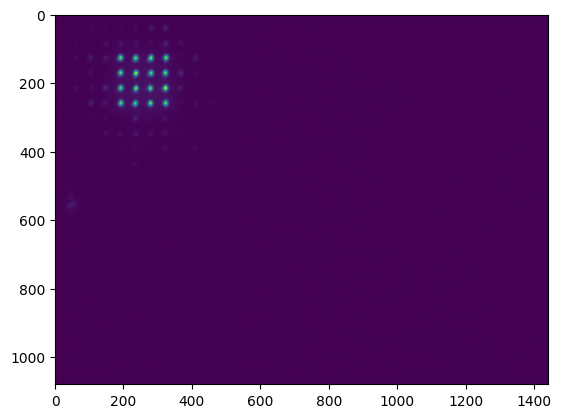

In [294]:
plot_cam(fs=fs,phase = phis[9].numpy() + blaze_phase.numpy())